# Library import ar data load

In [1]:
import pandas as pd
import numpy as np

path = r"C:\Users\madhu\OneDrive\Desktop\collage ML\5G_Traffic_Datasets\Game_Streaming\GeForce_Now\GeForce_Now_merged.csv"

df = pd.read_csv(path)
print("Shape:", df.shape)
df.head()

Shape: (7338316, 8)


,No.,Time,Source,Destination,Protocol,Length,Info,source_file
0,436,2022-09-27 13:08:31.564846,10.215.173.1,112.217.128.200,TCP,60,58632 > 443 [SYN] Seq=0 Win=65535 Len=0 MSS=...,GeForce_Now_1.csv
1,443,2022-09-27 13:08:31.593193,112.217.128.200,10.215.173.1,TCP,48,"443 > 58632 [SYN, ACK] Seq=0 Ack=1 Win=2048 ...",GeForce_Now_1.csv
2,444,2022-09-27 13:08:31.593329,10.215.173.1,112.217.128.200,TCP,40,58632 > 443 [ACK] Seq=1 Ack=1 Win=79872 Len=0,GeForce_Now_1.csv
3,445,2022-09-27 13:08:31.594817,10.215.173.1,112.217.128.200,TLSv1.2,557,Client Hello,GeForce_Now_1.csv
4,446,2022-09-27 13:08:31.594972,112.217.128.200,10.215.173.1,TCP,40,443 > 58632 [ACK] Seq=1 Ack=518 Win=2096128 ...,GeForce_Now_1.csv


# Inspect the data

In [2]:
df.info()                                   # column types and non-null counts
print(df.columns.tolist())                  # all column names
missing = df.isnull().sum()
print(missing[missing > 0])                 # columns with missing values
print("Duplicates:", df.duplicated().sum())
df.describe().T

<class 'pandas.DataFrame'>
RangeIndex: 7338316 entries, 0 to 7338315
Data columns (total 8 columns):
 #   Column       Dtype
---  ------       -----
 0   No.          int64
 1   Time         str  
 2   Source       str  
 3   Destination  str  
 4   Protocol     str  
 5   Length       int64
 6   Info         str  
 7   source_file  str  
dtypes: int64(2), str(6)
memory usage: 1.1 GB
['No.', 'Time', 'Source', 'Destination', 'Protocol', 'Length', 'Info', 'source_file']
Info    107
dtype: int64
Duplicates: 0


,count,mean,std,min,25%,50%,75%,max
No.,7338316.0,1.888936e+06,1.084647e+06,214.0,957037.0,1874584.0,2792041.0,4036716.0
Length,7338316.0,8.527384e+02,5.333000e+02,36.0,329.0,1332.0,1332.0,10000.0


# Clean the data

In [3]:
# remove duplicate rows
df = df.drop_duplicates().reset_index(drop=True)

# fill missing numeric values with the median
num_cols = df.select_dtypes(include=np.number).columns
df[num_cols] = df[num_cols].fillna(df[num_cols].median())

# fill missing categorical values with the mode
cat_cols = df.select_dtypes(exclude=np.number).columns
for c in cat_cols:
    if df[c].isnull().any():
        df[c] = df[c].fillna(df[c].mode()[0])

print("After cleaning:", df.shape)

After cleaning: (7338316, 8)


# Check the target column

In [4]:
print(df.columns.tolist())
print()
print(df.dtypes)
print()
print(df.nunique().sort_values())   # unique value count per column
df.head(3).T

['No.', 'Time', 'Source', 'Destination', 'Protocol', 'Length', 'Info', 'source_file']

No.            int64
Time             str
Source           str
Destination      str
Protocol         str
Length         int64
Info             str
source_file      str
dtype: object

source_file          2
Destination          3
Source               3
Protocol             7
Length            1296
Info              6997
No.            4036159
Time           7338316
dtype: int64


,0,1,2
No.,436,443,444
Time,2022-09-27 13:08:31.564846,2022-09-27 13:08:31.593193,2022-09-27 13:08:31.593329
Source,10.215.173.1,112.217.128.200,10.215.173.1
Destination,112.217.128.200,10.215.173.1,112.217.128.200
Protocol,TCP,TCP,TCP
Length,60,48,40
Info,58632 > 443 [SYN] Seq=0 Win=65535 Len=0 MSS=...,"443 > 58632 [SYN, ACK] Seq=0 Ack=1 Win=2048 ...",58632 > 443 [ACK] Seq=1 Ack=1 Win=79872 Len=0
source_file,GeForce_Now_1.csv,GeForce_Now_1.csv,GeForce_Now_1.csv


# Build features

In [5]:
# keep only the columns we need
data = df[["Time", "Source", "Protocol", "Length"]].copy()

# inter-arrival time between consecutive packets (seconds)
data["Time"] = pd.to_datetime(data["Time"])
data["iat"] = data["Time"].diff().dt.total_seconds().fillna(0).clip(lower=0)

# direction: 1 = uplink (client sends), 0 = downlink (server sends)
data["direction"] = (data["Source"] == "10.215.173.1").astype(int)

data = data.drop(columns=["Time", "Source"])
print(data["Protocol"].value_counts())

Protocol
UDP         7330803
TCP            3664
TLSv1.2        3662
RTCP            184
Pathport          1
THRIFT            1
DCP-PFT           1
Name: count, dtype: int64


# balance check, sample, split, train, evaluate

Source
112.217.128.200    3430593
112.217.128.202    2968327
10.215.173.1        939396
Name: count, dtype: int64

direction
0    6398920
1     939396
Name: count, dtype: int64
direction
0    0.872
1    0.128
Name: proportion, dtype: float64

Train/Test: (800000, 2) (200000, 2)

               precision    recall  f1-score   support

    downlink       1.00      0.99      0.99    174310
      uplink       0.93      0.99      0.96     25690

    accuracy                           0.99    200000
   macro avg       0.96      0.99      0.98    200000
weighted avg       0.99      0.99      0.99    200000

Macro F1: 0.9754


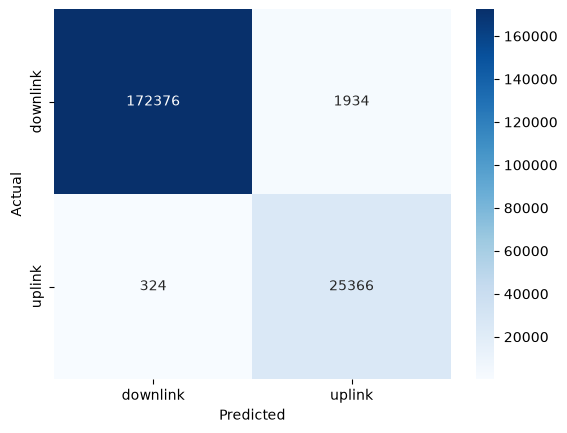

In [6]:
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, confusion_matrix, f1_score

# check source IPs and direction balance
print(df["Source"].value_counts())
print()
print(data["direction"].value_counts())
print(data["direction"].value_counts(normalize=True).round(3))

# 1M random sample for a faster first run
sample = data.sample(n=1_000_000, random_state=42)
X = sample[["Length", "iat"]]
y = sample["direction"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=42
)
print("\nTrain/Test:", X_train.shape, X_test.shape)

# train baseline model
rf = RandomForestClassifier(
    n_estimators=100,
    max_depth=20,
    class_weight="balanced",
    n_jobs=-1,
    random_state=42,
)
rf.fit(X_train, y_train)

# evaluate
y_pred = rf.predict(X_test)
labels = ["downlink", "uplink"]

print("\n", classification_report(y_test, y_pred, target_names=labels))
print("Macro F1:", round(f1_score(y_test, y_pred, average="macro"), 4))

cm = confusion_matrix(y_test, y_pred)
sns.heatmap(cm, annot=True, fmt="d", xticklabels=labels, yticklabels=labels, cmap="Blues")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()

Train uplink share: 0.132 | Test uplink share: 0.114
              precision    recall  f1-score   support

    downlink       1.00      0.99      1.00    265829
      uplink       0.95      0.99      0.97     34171

    accuracy                           0.99    300000
   macro avg       0.97      0.99      0.98    300000
weighted avg       0.99      0.99      0.99    300000

Macro F1: 0.9812
Length           0.748
iat              0.180
len_roll_mean    0.038
len_roll_std     0.021
iat_roll_mean    0.013
dtype: float64


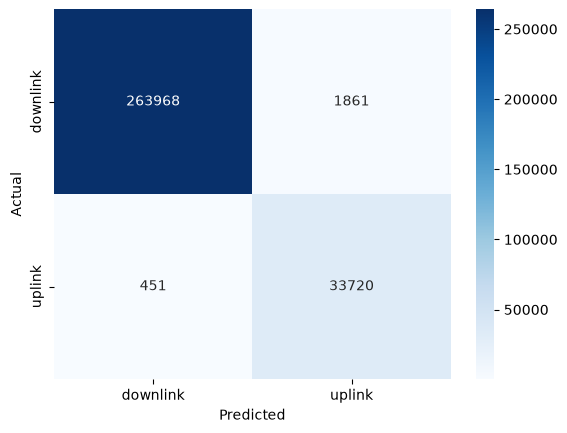

In [7]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, confusion_matrix, f1_score
import seaborn as sns
import matplotlib.pyplot as plt
import pandas as pd

# context features from the previous 10 packets
data["len_roll_mean"] = data["Length"].rolling(10).mean().fillna(data["Length"])
data["len_roll_std"] = data["Length"].rolling(10).std().fillna(0)
data["iat_roll_mean"] = data["iat"].rolling(10).mean().fillna(0)

features = ["Length", "iat", "len_roll_mean", "len_roll_std", "iat_roll_mean"]

# time-based split: first 80% of the capture for train, last 20% for test
split_idx = int(len(data) * 0.8)
train = data.iloc[:split_idx].sample(n=1_000_000, random_state=42)
test = data.iloc[split_idx:].sample(n=300_000, random_state=42)

X_train, y_train = train[features], train["direction"]
X_test, y_test = test[features], test["direction"]
print("Train uplink share:", round(y_train.mean(), 3), "| Test uplink share:", round(y_test.mean(), 3))

# train
rf2 = RandomForestClassifier(
    n_estimators=100,
    max_depth=20,
    class_weight="balanced",
    n_jobs=-1,
    random_state=42,
)
rf2.fit(X_train, y_train)

# evaluate
y_pred = rf2.predict(X_test)
labels = ["downlink", "uplink"]
print(classification_report(y_test, y_pred, target_names=labels))
print("Macro F1:", round(f1_score(y_test, y_pred, average="macro"), 4))

# feature importance
print(pd.Series(rf2.feature_importances_, index=features).sort_values(ascending=False).round(3))

cm = confusion_matrix(y_test, y_pred)
sns.heatmap(cm, annot=True, fmt="d", xticklabels=labels, yticklabels=labels, cmap="Blues")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()

Train: (300000, 5) | Test: (200000, 5)
Train uplink share: 0.132 | Test uplink share: 0.115
Done: Logistic Regression
Done: Decision Tree
Done: Random Forest
Done: Hist Gradient Boosting
                 Model  Accuracy  Macro F1  Uplink Precision  Uplink Recall  Train Time (s)
         Decision Tree    0.9901    0.9762            0.9287         0.9894          0.7865
         Random Forest    0.9900    0.9760            0.9294         0.9876          8.9255
Hist Gradient Boosting    0.9878    0.9710            0.9139         0.9866          4.9649
   Logistic Regression    0.7311    0.6276            0.2846         0.8905          0.1750


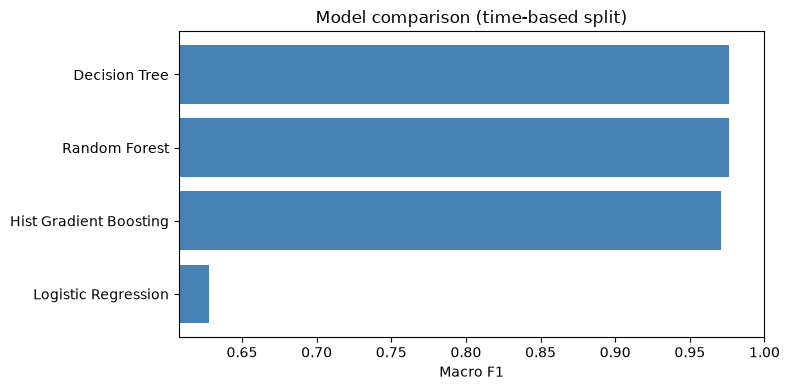

In [8]:
import gc
import time
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.utils.class_weight import compute_sample_weight
from sklearn.metrics import accuracy_score, f1_score, precision_score, recall_score

path = r"C:\Users\madhu\OneDrive\Desktop\collage ML\5G_Traffic_Datasets\Game_Streaming\GeForce_Now\GeForce_Now_merged.csv"

# load only the needed columns
raw = pd.read_csv(
    path,
    usecols=["Time", "Source", "Length"],
    dtype={"Length": "int32"},
    parse_dates=["Time"],
)

# build features and target with small dtypes
data = pd.DataFrame({
    "Length": raw["Length"].astype("float32"),
    "iat": raw["Time"].diff().dt.total_seconds().fillna(0).clip(lower=0).astype("float32"),
    "direction": (raw["Source"] == "10.215.173.1").astype("int8"),
})
del raw
gc.collect()

# context features from the previous 10 packets
data["len_roll_mean"] = data["Length"].rolling(10, min_periods=1).mean().astype("float32")
data["len_roll_std"] = data["Length"].rolling(10, min_periods=2).std().fillna(0).astype("float32")
data["iat_roll_mean"] = data["iat"].rolling(10, min_periods=1).mean().astype("float32")

features = ["Length", "iat", "len_roll_mean", "len_roll_std", "iat_roll_mean"]

# time-based split: first 80% for train, last 20% for test
split_idx = int(len(data) * 0.8)
train = data.iloc[:split_idx].sample(n=300_000, random_state=42)
test = data.iloc[split_idx:].sample(n=200_000, random_state=42)

X_train, y_train = train[features], train["direction"]
X_test, y_test = test[features], test["direction"]
del data, train, test
gc.collect()

print("Train:", X_train.shape, "| Test:", X_test.shape)
print("Train uplink share:", round(y_train.mean(), 3), "| Test uplink share:", round(y_test.mean(), 3))

# models (kept small to save memory)
models = {
    "Logistic Regression": make_pipeline(
        StandardScaler(),
        LogisticRegression(class_weight="balanced", max_iter=1000),
    ),
    "Decision Tree": DecisionTreeClassifier(
        max_depth=15, min_samples_leaf=10, class_weight="balanced", random_state=42
    ),
    "Random Forest": RandomForestClassifier(
        n_estimators=50, max_depth=15, min_samples_leaf=10,
        class_weight="balanced", n_jobs=2, random_state=42
    ),
    "Hist Gradient Boosting": HistGradientBoostingClassifier(random_state=42),
}

sample_w = compute_sample_weight("balanced", y_train)

rows = []
for name, model in models.items():
    start = time.time()
    if name == "Hist Gradient Boosting":
        model.fit(X_train, y_train, sample_weight=sample_w)
    else:
        model.fit(X_train, y_train)
    train_time = time.time() - start

    pred = model.predict(X_test)
    rows.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, pred),
        "Macro F1": f1_score(y_test, pred, average="macro"),
        "Uplink Precision": precision_score(y_test, pred, pos_label=1),
        "Uplink Recall": recall_score(y_test, pred, pos_label=1),
        "Train Time (s)": train_time,
    })
    print(f"Done: {name}")

results = pd.DataFrame(rows).sort_values("Macro F1", ascending=False).reset_index(drop=True)
print(results.round(4).to_string(index=False))

# bar chart of macro F1
plt.figure(figsize=(8, 4))
plt.barh(results["Model"][::-1], results["Macro F1"][::-1], color="steelblue")
plt.xlabel("Macro F1")
plt.xlim(results["Macro F1"].min() - 0.02, 1.0)
plt.title("Model comparison (time-based split)")
plt.tight_layout()
plt.show()

Decision Tree: folds = [0.9736 0.9659 0.9721 0.9768 0.979 ] | mean = 0.9735 +/- 0.0045
Random Forest: folds = [0.9739 0.9659 0.9675 0.9753 0.9764] | mean = 0.9718 +/- 0.0043

Best params: {'min_samples_leaf': 1, 'max_depth': 20, 'criterion': 'entropy'}
Best CV macro F1: 0.9777

               precision    recall  f1-score   support

    downlink       1.00      0.99      0.99    177088
      uplink       0.95      0.97      0.96     22912

    accuracy                           0.99    200000
   macro avg       0.97      0.98      0.98    200000
weighted avg       0.99      0.99      0.99    200000

Test macro F1: 0.978
Length           0.848
iat              0.130
iat_roll_mean    0.008
len_roll_mean    0.008
len_roll_std     0.005
dtype: float64


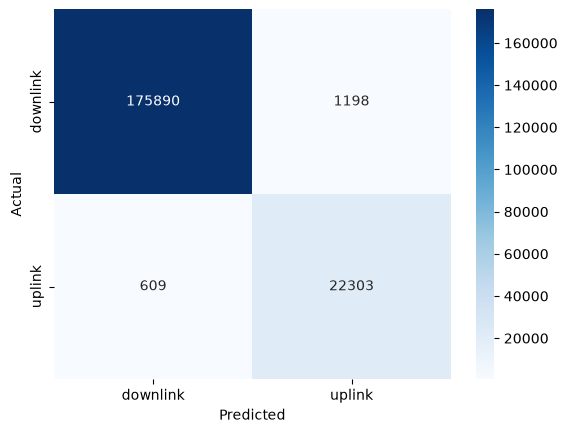

Saved to: c:\Users\madhu\OneDrive\Desktop\collage ML\5G_Traffic_Datasets\Game_Streaming\GeForce_Now\direction_classifier.joblib


In [9]:
import os
import joblib
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import TimeSeriesSplit, cross_val_score, RandomizedSearchCV
from sklearn.metrics import classification_report, confusion_matrix, f1_score

# restore time order of the sampled training rows (index = original row position)
X_tr = X_train.sort_index()
y_tr = y_train.loc[X_tr.index]

tscv = TimeSeriesSplit(n_splits=5)

# 1) time-series cross-validation of the top two models
candidates = [
    ("Decision Tree", DecisionTreeClassifier(
        max_depth=15, min_samples_leaf=10, class_weight="balanced", random_state=42)),
    ("Random Forest", RandomForestClassifier(
        n_estimators=50, max_depth=15, min_samples_leaf=10,
        class_weight="balanced", n_jobs=2, random_state=42)),
]
for name, model in candidates:
    scores = cross_val_score(model, X_tr, y_tr, cv=tscv, scoring="f1_macro")
    print(f"{name}: folds = {scores.round(4)} | mean = {scores.mean():.4f} +/- {scores.std():.4f}")

# 2) light hyperparameter tuning of the Decision Tree
param_grid = {
    "max_depth": [8, 10, 12, 15, 20, 25],
    "min_samples_leaf": [1, 5, 10, 20, 50],
    "criterion": ["gini", "entropy"],
}
search = RandomizedSearchCV(
    DecisionTreeClassifier(class_weight="balanced", random_state=42),
    param_grid, n_iter=15, cv=tscv, scoring="f1_macro",
    random_state=42, n_jobs=2,
)
search.fit(X_tr, y_tr)
print("\nBest params:", search.best_params_)
print("Best CV macro F1:", round(search.best_score_, 4))
best = search.best_estimator_

# 3) final evaluation on the untouched test set
y_pred = best.predict(X_test)
labels = ["downlink", "uplink"]
print("\n", classification_report(y_test, y_pred, target_names=labels))
print("Test macro F1:", round(f1_score(y_test, y_pred, average="macro"), 4))
print(pd.Series(best.feature_importances_, index=features).sort_values(ascending=False).round(3))

cm = confusion_matrix(y_test, y_pred)
sns.heatmap(cm, annot=True, fmt="d", xticklabels=labels, yticklabels=labels, cmap="Blues")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()

# 4) save the model together with what is needed to reuse it
joblib.dump(
    {"model": best, "features": features, "client_ip": "10.215.173.1", "labels": labels},
    "direction_classifier.joblib",
)
print("Saved to:", os.path.abspath("direction_classifier.joblib"))

                 Model  Accuracy  Macro F1  Uplink Precision  Uplink Recall  Uplink F1
 Decision Tree (tuned)    0.9910    0.9780            0.9490         0.9734     0.9611
         Decision Tree    0.9901    0.9762            0.9287         0.9894     0.9581
         Random Forest    0.9900    0.9760            0.9294         0.9876     0.9576
Hist Gradient Boosting    0.9878    0.9710            0.9139         0.9866     0.9489
   Logistic Regression    0.7311    0.6276            0.2846         0.8905     0.4314


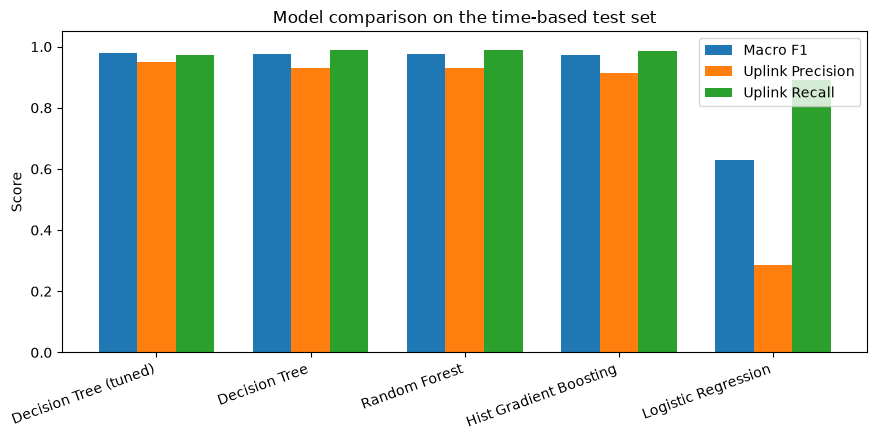

In [10]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import accuracy_score, f1_score, precision_score, recall_score

all_models = dict(models)
all_models["Decision Tree (tuned)"] = best

rows = []
for name, model in all_models.items():
    pred = model.predict(X_test)
    rows.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, pred),
        "Macro F1": f1_score(y_test, pred, average="macro"),
        "Uplink Precision": precision_score(y_test, pred, pos_label=1),
        "Uplink Recall": recall_score(y_test, pred, pos_label=1),
        "Uplink F1": f1_score(y_test, pred, pos_label=1),
    })

final = pd.DataFrame(rows).sort_values("Macro F1", ascending=False).reset_index(drop=True)
print(final.round(4).to_string(index=False))
final.round(4).to_csv("model_comparison.csv", index=False)

# grouped bar chart
x = list(range(len(final)))
w = 0.25
plt.figure(figsize=(9, 4.5))
plt.bar([i - w for i in x], final["Macro F1"], w, label="Macro F1")
plt.bar(x, final["Uplink Precision"], w, label="Uplink Precision")
plt.bar([i + w for i in x], final["Uplink Recall"], w, label="Uplink Recall")
plt.xticks(x, final["Model"], rotation=20, ha="right")
plt.ylim(0, 1.05)
plt.ylabel("Score")
plt.title("Model comparison on the time-based test set")
plt.legend()
plt.tight_layout()
plt.savefig("model_comparison.png", dpi=150)
plt.show()

| Model | Accuracy | Macro F1 | Uplink Precision | Uplink Recall | Uplink F1 |
|---|---|---|---|---|---|
| Decision Tree (tuned) | **0.9910** | **0.9780** | **0.9490** | 0.9734 | **0.9611** |
| Decision Tree | 0.9901 | 0.9762 | 0.9287 | **0.9894** | 0.9581 |
| Random Forest | 0.9900 | 0.9760 | 0.9294 | 0.9876 | 0.9576 |
| Hist Gradient Boosting | 0.9878 | 0.9710 | 0.9139 | 0.9866 | 0.9489 |
| Logistic Regression | 0.7311 | 0.6276 | 0.2846 | 0.8905 | 0.4314 |

In [11]:
import joblib

saved = joblib.load("direction_classifier.joblib")
print(saved["features"], saved["labels"])
print(saved["model"])

['Length', 'iat', 'len_roll_mean', 'len_roll_std', 'iat_roll_mean'] ['downlink', 'uplink']
DecisionTreeClassifier(class_weight='balanced', criterion='entropy',
                       max_depth=20, random_state=42)
